# Salario mínimo y privación material de quienes trabajan

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "smi-pobreza-laboral"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Salario mínimo y privación material de quienes trabajan"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ue27"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Salario mínimo legal", "unidad": "% del salario mediano a tiempo completo"}
EJE_Y = {"titulo": "Personas ocupadas con privación material y social severa", "unidad": "% de las personas ocupadas de 18 años o más"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la UE con salario mínimo legal nacional y dato en los dos ejes.

- **Eje horizontal:** el **salario mínimo legal** en porcentaje del salario mediano de los trabajadores a tiempo completo del mismo país (el mismo eje que `smi-empleo-juvenil`).
- **Eje vertical:** el porcentaje de las **personas ocupadas de 18 años o más con privación material y social severa**: no pueden permitirse al menos 7 de 13 gastos que la UE considera básicos (por ejemplo, mantener la vivienda a una temperatura adecuada, afrontar un gasto imprevisto o pagar a tiempo el alquiler o la hipoteca).

**Por qué este eje y no el riesgo de pobreza.** El riesgo de pobreza se mide con un umbral relativo (el 60 % de la renta mediana), igual que el eje x se mide respecto al salario mediano: los dos dependen de la mediana. La privación material es una medida absoluta, la misma lista de carencias en todos los países, así que no depende de la mediana (por indicación humana del 2026-10-18). El riesgo de pobreza de los ocupados de España queda en las notas.

**Para qué sirve.** Es el argumento de quienes defienden subir el salario mínimo: que mejora las condiciones de vida de quienes trabajan. Quienes proponen no subirlo o fijarlo con otro criterio sostienen que las carencias dependen más de la composición del hogar que del salario y que puede reducir el empleo (la otra lectura está en `smi-empleo-juvenil`). **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- La privación se mide en todo el hogar y no solo con el salario: una persona con salario mínimo puede no sufrir carencias si en su hogar hay otros ingresos, y al revés.
- Las carencias dependen también del nivel de vida general del país (los países con menos renta tienen más privación), no solo del salario mínimo.
- La serie con la definición actual empieza en 2015.
- Solo entran los países de la UE con salario mínimo legal nacional publicado por la OCDE.

## 2. Descarga

- **OCDE, Minimum relative to average wages of full-time workers** (`OECD.ELS.SAE,DSD_EARNINGS@MIN2AVE`, versión 1.0): salario mínimo en % del salario mediano a tiempo completo (mediana), para los países de la UE que publica la OCDE.
- **Eurostat, encuesta de condiciones de vida** (`ilc_mdsd12`): tasa de privación material y social severa de las personas ocupadas (`EMP`, situación laboral más frecuente), ambos sexos, 18 años o más (`Y_GE18`), en % (`PC`).
- **Eurostat** (`ilc_iw01`): tasa de riesgo de pobreza de las personas ocupadas, solo para las notas.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Salario mínimo legal en % del salario mediano a tiempo completo (OCDE, Minimum relative to average wages)
DATAFLOW_MIN = "OECD.ELS.SAE,DSD_EARNINGS@MIN2AVE,1.0"
# Dimensiones: país . medida . unidad . periodo de pago . base de precios . operación estadística . sexo
CLAVE_MIN = "{AREA}.MR_WG_FT.PT_WG_A_SAL_FT._Z._Z.MEDIAN._Z"

# Privación material y social severa de las personas ocupadas (Eurostat, encuesta de condiciones de vida)
from lib.paises import CODIGOS_EUROSTAT

GEOS_ES = {CODIGOS_EUROSTAT[c]: c for c in PAISES}  # código Eurostat (alfa-2, EL = Grecia) -> código del país
x, _ = oecd.get(DATAFLOW_MIN, CLAVE_MIN, areas=AREAS, desde=DESDE)
y, fuentes_y = eurostat.get(
    "ilc_mdsd12", {"freq": "A", "wstatus": "EMP", "sex": "T", "age": "Y_GE18", "unit": "PC"},
    geos=GEOS_ES, desde=DESDE,
)
# Riesgo de pobreza de los ocupados, solo para las notas
pobreza, _ = eurostat.get(
    "ilc_iw01", {"freq": "A", "wstatus": "EMP", "sex": "T", "age": "Y_GE18", "unit": "PC"},
    geos=GEOS_ES, desde=DESDE,
)
print("Países de la UE con salario mínimo:", x["serie"].nunique(), "· con privación de los ocupados:", y["serie"].nunique())

Países de la UE con salario mínimo: 20 · con privación de los ocupados: 27


## 3. Transformación

1. El eje x es el mismo salario mínimo de `smi-empleo-juvenil`; el eje y es el de Eurostat (`ilc_mdsd12`), sin transformar.
2. **Sin punto de las medias:** la OCDE no publica el salario mínimo relativo para la UE-27 (solo para los países con salario mínimo legal).
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.
4. Para las notas: los países de la UE sin salario mínimo legal nacional o sin dato en la fuente, y el riesgo de pobreza de los ocupados de España en el año de su punto.

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


def notas_min(x):
    """Notas comunes del eje del salario mínimo (OCDE, MIN2AVE)."""
    _, flujo, version = DATAFLOW_MIN.split(",")
    return [
        f"Salario mínimo: OCDE, Minimum relative to average wages of full-time workers ({flujo}, versión {version}): "
        "salario mínimo legal nacional en porcentaje del salario mediano de los trabajadores a tiempo completo "
        "(MR_WG_FT, PT_WG_A_SAL_FT, mediana). Solo publica los países con salario mínimo legal nacional.",
        "En Estados Unidos, la OCDE usa el salario mínimo federal, que varios estados superan con el suyo.",
    ]


_, FLUJO_MIN, VERSION_MIN = DATAFLOW_MIN.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_MIN} (Minimum relative to average wages, versión {VERSION_MIN}): MR_WG_FT, PT_WG_A_SAL_FT, mediana", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", eurostat.ORGANISMO, "ilc_mdsd12 (wstatus=EMP, sex=T, age=Y_GE18, unit=PC)", eurostat.URL_DATABROWSER.format(dataset="ilc_mdsd12"), HOY),
]
puntos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=[],
    generado_por="", desde=DESDE, anios=ANIOS,
)["puntos"]
a_esp = next(p["anio"] for p in puntos if p["codigo"] == "ESP")
pobreza_esp = pobreza.set_index(["serie", "periodo"])["valor"].get(("ESP", a_esp))
sin_minimo = sorted(nombre_punto(c) for c in set(PAISES) - set(x["serie"]))
NOTAS = notas_min(x)[:1] + [
    "Privación material y social severa de las personas ocupadas: Eurostat, encuesta de condiciones de vida "
    "(ilc_mdsd12): personas ocupadas de 18 años o más (situación laboral más frecuente del año anterior) que no "
    "pueden permitirse al menos 7 de los 13 elementos de la lista de la UE, en porcentaje de las personas ocupadas. "
    "Es la misma lista en todos los países, a diferencia del riesgo de pobreza, que se mide respecto a la renta "
    "mediana de cada país. Serie desde 2015.",
    f"Riesgo de pobreza de las personas ocupadas de España en {a_esp} (Eurostat, ilc_iw01: renta equivalente del "
    f"hogar inferior al 60 % de la mediana): {es(pobreza_esp)} %. No se usa en el eje porque, como el salario mínimo "
    "del eje x, se mide respecto a la mediana.",
    f"La OCDE no publica salario mínimo para {len(sin_minimo)} de los {len(PAISES)} países de la UE-27 (la lista está en "
    "la nota de países sin dato): los países de la UE sin salario mínimo legal nacional, como los nórdicos, Austria o "
    "Italia, lo fijan por convenio colectivo, y otros no están en la base de la OCDE.",
    "La privación se mide en todo el hogar y no solo por el salario de la persona ocupada, y depende también del "
    "nivel de vida general de cada país.",
]

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

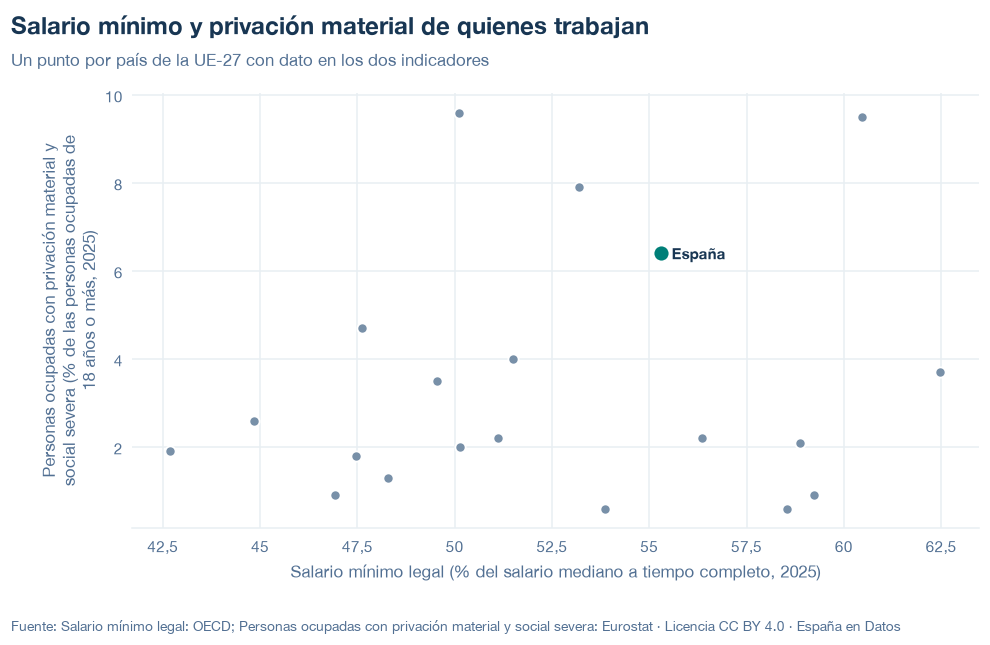

codigo  anio         x   y
   BEL  2025 47.470750 1.8
   BGR  2025 53.201354 7.9
   CZE  2025 46.913413 0.9
   DEU  2025 49.555057 3.5
   ESP  2025 55.301258 6.4
   EST  2025 42.698416 1.9
   FRA  2025 62.483821 3.7
   GRC  2025 50.101757 9.6
   HRV  2025 53.859570 0.6
   HUN  2025 47.625665 4.7
   IRL  2025 51.120622 2.2
   LTU  2025 50.135716 2.0
   LUX  2025 56.352517 2.2
   LVA  2025 44.848736 2.6
   NLD  2025 48.296957 1.3
   POL  2025 59.233037 0.9
   PRT  2025 58.878413 2.1
   ROU  2025 60.475531 9.5
   SVK  2025 51.509323 4.0
   SVN  2025 58.535604 0.6


In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/smi-pobreza-laboral.json y data/smi-pobreza-laboral.csv


## 6. Fuentes, notas y licencia

- OCDE, Minimum relative to average wages of full-time workers: `OECD.ELS.SAE,DSD_EARNINGS@MIN2AVE,1.0` (`MR_WG_FT`, `PT_WG_A_SAL_FT`, `MEDIAN`).
- Eurostat, `ilc_mdsd12` (`EMP`, `T`, `Y_GE18`, `PC`); `ilc_iw01` (mismas dimensiones), solo para las notas.

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.